# 05 · Vehicle Routing

From one vehicle to a fleet. The **vehicle-routing problem** sends several vehicles out from a
depot, each with a capacity, to serve every stop once. Its extension adds **delivery time
windows**. This is where exact methods are hopeless at real sizes and heuristics are essential —
we solve it with OR-Tools guided local search.

This is also the last-mile layer of a supply chain: `supply_chain_arena` decides *where* facilities
sit and *how much* inventory they hold; routing moves the goods the final step. The VRP is the
handoff.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from src.ortools_solver.routing import solve_vrp
from src.problems.vrp import generate_vrp_instance
from src.reporting import save_figure, save_json
from src.visualisation import plot_vrp_solution

SEED = 42
CUSTOMERS = 20
VEHICLES = 4
CAPACITY = 50
TIME_LIMIT = 3.0


def route_report(instance, solution):
    rows = []
    for v, route in enumerate(solution.routes):
        if len(route) <= 2:
            continue
        load = int(sum(int(instance.demands[node]) for node in route))
        dist = float(sum(instance.distances[route[i], route[i + 1]]
                         for i in range(len(route) - 1)))
        rows.append({"vehicle": v, "stops": [int(n) for n in route],
                     "load": load, "capacity": instance.vehicle_capacity, "distance": dist})
    return rows

## 1. A capacitated fleet

Twenty customers, four vehicles, capacity 50 each. Every stop served once, no vehicle overloaded.

In [2]:
instance = generate_vrp_instance(CUSTOMERS, VEHICLES, CAPACITY, seed=SEED)
solution = solve_vrp(instance, time_limit=TIME_LIMIT)
rows = route_report(instance, solution)

visited = sorted(n for route in solution.routes for n in route if n != instance.depot)
feasible = {
    "every_customer_once": visited == list(range(1, CUSTOMERS + 1)),
    "capacity_respected": all(r["load"] <= CAPACITY for r in rows),
    "vehicles_used_within_fleet": solution.num_vehicles_used <= VEHICLES,
}
print(f"total demand {instance.total_demand} / fleet capacity {VEHICLES * CAPACITY}")
for r in rows:
    print(f"  vehicle {r['vehicle']}: {len(r['stops']) - 2:>2} stops  "
          f"load {r['load']:>3}/{CAPACITY}  distance {r['distance']:6.1f}")
print(f"total distance {solution.total_distance:.1f}  ·  feasible {all(feasible.values())}")

save_json("05_capacitated_vrp", {
    "seed": SEED, "customers": CUSTOMERS, "vehicles": VEHICLES, "capacity": CAPACITY,
    "total_demand": instance.total_demand, "total_distance": solution.total_distance,
    "num_vehicles_used": solution.num_vehicles_used, "routes": rows, "feasibility": feasible,
})

total demand 116 / fleet capacity 200
  vehicle 1:  6 stops  load  42/50  distance  154.8
  vehicle 2:  8 stops  load  41/50  distance  178.0
  vehicle 3:  6 stops  load  33/50  distance  127.7
total distance 460.4  ·  feasible True


PosixPath('/workspaces/routing_arena/outputs/data/05_capacitated_vrp.json')

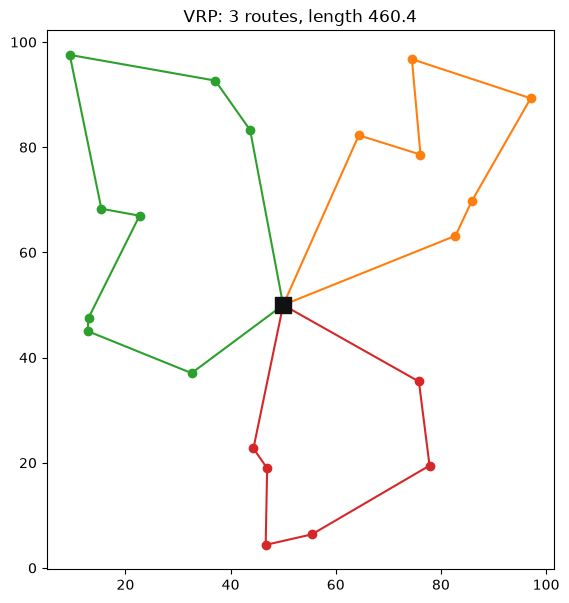

In [3]:
fig, ax = plt.subplots(figsize=(7, 7))
plot_vrp_solution(instance, solution, ax=ax)
save_figure(fig, "05_capacitated_vrp")
plt.show()

## 2. Adding time windows

Each customer now has an interval `[earliest, latest]` in which it must be served; a vehicle may
arrive early and wait. The exact MILP from notebook 02 cannot touch this at scale, but guided local
search handles it directly.

In [4]:
tw_instance = generate_vrp_instance(CUSTOMERS, VEHICLES, CAPACITY, seed=SEED,
                                    with_time_windows=True)
tw_solution = solve_vrp(tw_instance, time_limit=TIME_LIMIT, use_time_windows=True)
tw_rows = route_report(tw_instance, tw_solution)

# Reconstruct arrival times and confirm every window is respected.
schedules = []
windows_ok = True
for route in tw_solution.routes:
    if len(route) <= 2:
        continue
    clock, prev, legs = 0.0, route[0], []
    for node in route[1:]:
        clock += float(tw_instance.distances[prev, node])
        if node != tw_instance.depot:
            earliest, latest = tw_instance.time_windows[node]
            clock = max(clock, float(earliest))
            windows_ok = windows_ok and clock <= float(latest) + 1e-6
            legs.append({"stop": int(node), "arrival": round(clock, 1),
                         "window": [round(float(earliest), 1), round(float(latest), 1)]})
        prev = node
    schedules.append(legs)

print(f"time windows respected: {windows_ok}")
print(f"total distance with windows: {tw_solution.total_distance:.1f} "
      f"(vs {solution.total_distance:.1f} without)")

save_json("05_time_window_vrp", {
    "seed": SEED, "customers": CUSTOMERS, "vehicles": VEHICLES, "capacity": CAPACITY,
    "total_distance": tw_solution.total_distance, "num_vehicles_used": tw_solution.num_vehicles_used,
    "windows_respected": windows_ok, "routes": tw_rows, "schedules": schedules,
})

time windows respected: True
total distance with windows: 531.0 (vs 460.4 without)


PosixPath('/workspaces/routing_arena/outputs/data/05_time_window_vrp.json')

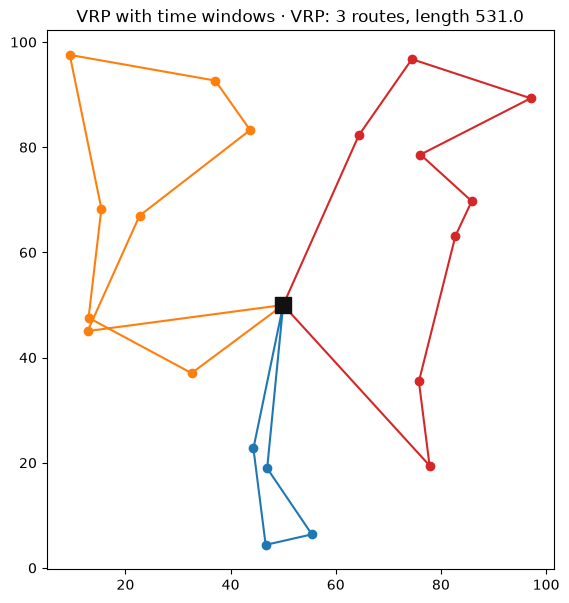

In [5]:
fig, ax = plt.subplots(figsize=(7, 7))
plot_vrp_solution(tw_instance, tw_solution, ax=ax)
ax.set_title("VRP with time windows · " + ax.get_title())
save_figure(fig, "05_time_window_vrp")
plt.show()

## 3. The fleet-size trade-off

More vehicles means shorter total driving but more trucks to pay for. We sweep the fleet size.

3 vehicles -> used 3, total distance 460.4


4 vehicles -> used 3, total distance 460.4


5 vehicles -> used 3, total distance 460.4


6 vehicles -> used 3, total distance 460.4


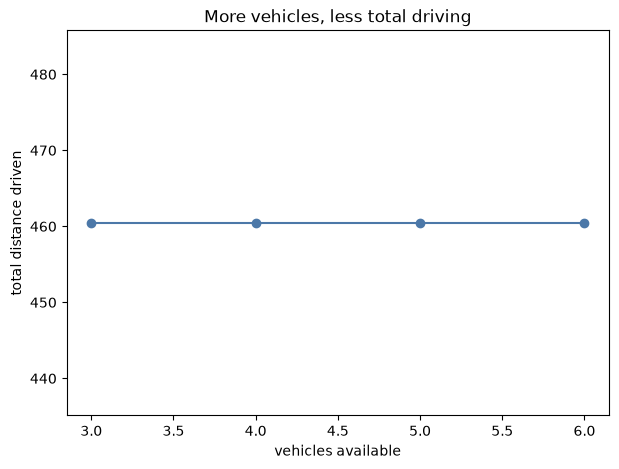

In [6]:
fleet_rows = []
for k in [3, 4, 5, 6]:
    inst = generate_vrp_instance(CUSTOMERS, k, CAPACITY, seed=SEED)
    sol = solve_vrp(inst, time_limit=TIME_LIMIT)
    fleet_rows.append({"vehicles_available": k, "vehicles_used": sol.num_vehicles_used,
                       "total_distance": sol.total_distance})
    print(f"{k} vehicles -> used {sol.num_vehicles_used}, total distance {sol.total_distance:.1f}")

save_json("05_fleet_tradeoff", {"seed": SEED, "customers": CUSTOMERS, "capacity": CAPACITY,
                                "rows": fleet_rows})

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([r["vehicles_available"] for r in fleet_rows],
        [r["total_distance"] for r in fleet_rows], "-o", color="#4C78A8")
ax.set_xlabel("vehicles available")
ax.set_ylabel("total distance driven")
ax.set_title("More vehicles, less total driving")
save_figure(fig, "05_fleet_tradeoff")
plt.show()

## Takeaway

Real routing is the VRP, not the textbook TSP: capacities, a fleet, and time windows. No exact
solver touches it at the sizes a delivery operation runs daily, and OR-Tools' guided local search
handles all of it in seconds. This is the tool a logistics team actually uses — and the moment
`supply_chain_arena` hands the goods to the road.

Next: **06 · Arena and Decisions** — the scoreboard across every method and size, and the rule for
picking one.